In [1]:
from specml.data_processing import SpectroscopicData
from specml.visualization import plotting
import numpy as np
from specml.data_processing.mask import create_mask_from_area, apply_mask, rebuild_tissue_mask
from specml.data_processing.preprocessing import vector_norm, adjust_spectra_min_to_zero

test_data1 = SpectroscopicData(file_path=f'E:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt')

INFO:specml.data_processing.spectroscopic_data:Data loaded with shape (512, 1664, 754)
INFO:specml.data_processing.spectroscopic_data:{'filename': 'E:/Lung_Data_8cm/6F-6504-01/6F-6504-01_top2/6f-6504-01_top2.dmt', 'xpixels': 1664, 'ypixels': 512, 'xtiles': 13, 'ytiles': 4, 'numpts': 754, 'fpasize': 128}
INFO:specml.data_processing.spectroscopic_data:Spectroscopic data loaded successfully.
INFO:specml.data_processing.spectroscopic_data:--------------------------------------------------


In [2]:
from specml.feature_engineering.dim_reduction import apply_pca, apply_umap
from specml.ml_models.unsupervised import apply_kmeans
print(test_data1.data.shape)
test_data1 = test_data1.easy_preprocess() 
# test_data1.keep_range(1000, 1800)
print(test_data1.data.shape)

c:\Users\u37314kd\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:specml.data_processing.spectroscopic_data:Kept wavenumber range from 950 to 3550


(512, 1664, 754)


INFO:specml.data_processing.spectroscopic_data:Data flattened and mask applied. Shape of processed data: (851968, 673)
INFO:specml.data_processing.spectroscopic_data:Kept wavenumber range from 1000 to 1800


(446706, 206)


In [3]:
pca_result = apply_pca(test_data1, n_components=3)
# umap_result, umap_obj = apply_umap(test_data1.data, n_components=3)
kmeans_result= apply_kmeans(test_data1, n_clusters=5)

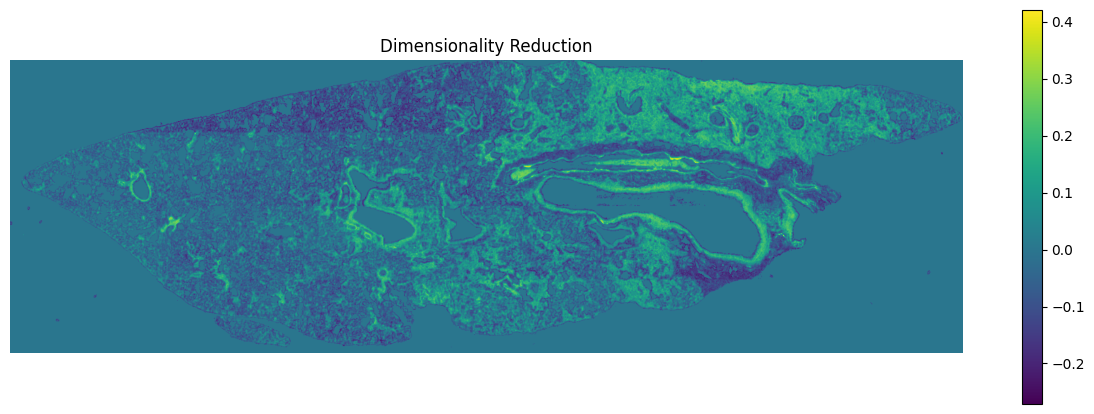

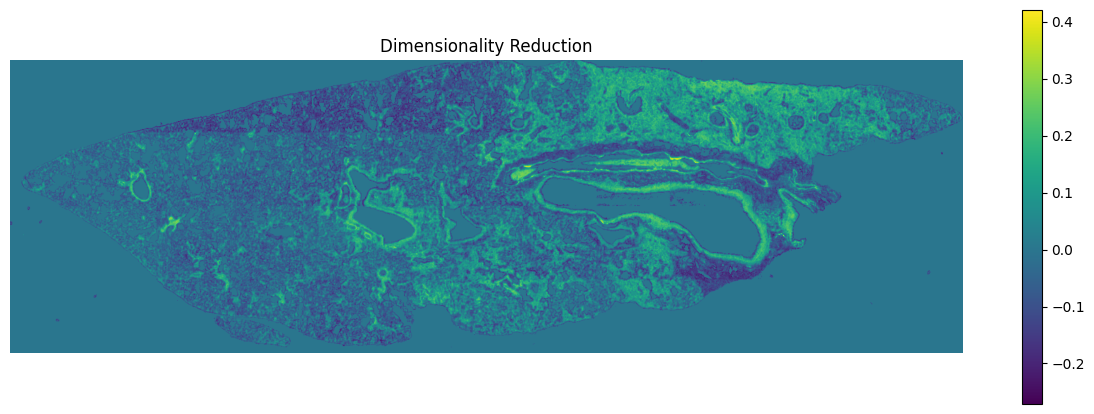

In [8]:
from specml.visualization.plotting import display_image, display_dim_reduction_as_image

# display_image(pca_result.reduced_data, ypixels=test_data1.ypixels, xpixels=test_data1.xpixels, title='PCA',)
# display_image(kmeans_result.cluster_labels, ypixels=test_data1.ypixels, xpixels=test_data1.xpixels, title='KMeans')
display_dim_reduction_as_image(pca_result)

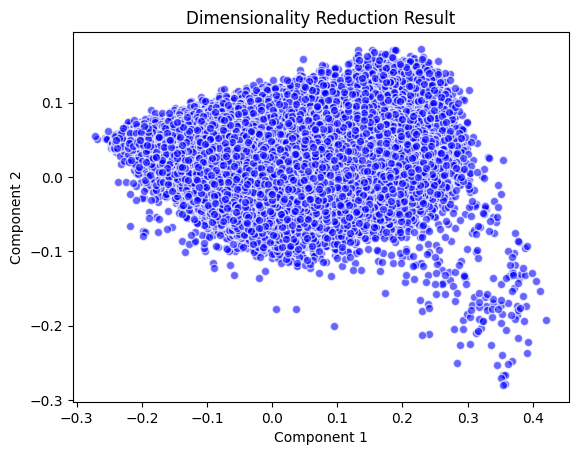

In [9]:
from specml.visualization.plotting import plot_dim_reduction_result
plot_dim_reduction_result(pca_result)